# Mean seasonal cycle — complete data

Monthly climatology of the complete field (`complete_data.nc`): the domain-mean climatology (same method as
`../harmonic.ipynb`), maps of each calendar month's average, and the 12 stacked maps saved
as `mean_seasonal_cycle.nc`.

In [1]:
import os
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

FIG_DIR = "../../Figures/climatology"
os.makedirs(FIG_DIR, exist_ok=True)

IN_NC  = "complete_data.nc"
OUT_NC = "mean_seasonal_cycle.nc"
TAG    = "complete"
mnames = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

field = xr.open_dataarray(IN_NC).load()
field

<xarray.DataArray 'co_mmr_midtrop' (time: 276, lat: 36, lon: 61)> Size: 5MB
array([[[9.13056653e-08, 9.08706497e-08, 9.07371103e-08, ...,
         8.76111415e-08, 8.80154758e-08, 8.81797817e-08],
        [9.20110210e-08, 9.17675465e-08, 9.15856049e-08, ...,
         8.69729604e-08, 8.71432988e-08, 8.77498394e-08],
        [9.32970465e-08, 9.28773360e-08, 9.26046226e-08, ...,
         8.65958469e-08, 8.68842278e-08, 8.73073418e-08],
        ...,
        [1.07297431e-07, 1.07621645e-07, 1.07818551e-07, ...,
         9.23793451e-08, 9.20941901e-08, 9.37570306e-08],
        [1.06856447e-07, 1.06780313e-07, 1.04458429e-07, ...,
         9.50967021e-08, 9.35234752e-08, 9.39973148e-08],
        [1.05869262e-07, 1.03086251e-07, 1.03755497e-07, ...,
         9.33793913e-08, 9.77393171e-08, 1.01747204e-07]],

       [[8.72969679e-08, 8.74599735e-08, 8.69653078e-08, ...,
         8.62969003e-08, 8.61778844e-08, 8.60296154e-08],
        [8.84877025e-08, 8.78902995e-08, 8.73903971e-08, ...,
         8.67971295e-08, 8.70615224e-08, 8.71106280e-08],
        [8.95211869e-08, 8.87518752e-08, 8.84018689e-08, ...,
         8.70693810e-08, 8.73863968e-08, 8.74123884e-08],
...
         7.95481157e-08, 7.81530218e-08, 7.86479433e-08],
        [8.24513862e-08, 8.28583282e-08, 8.21614492e-08, ...,
         8.01626996e-08, 7.93348889e-08, 7.88297356e-08],
        [8.32040641e-08, 8.28442595e-08, 8.26889277e-08, ...,
         8.00332742e-08, 8.05943969e-08, 8.06654299e-08]],

       [[7.42996065e-08, 7.40835020e-08, 7.33404448e-08, ...,
         7.56937197e-08, 7.59995515e-08, 7.64986723e-08],
        [7.32173362e-08, 7.39667811e-08, 7.36695753e-08, ...,
         7.43980593e-08, 7.51887654e-08, 7.55310623e-08],
        [7.34844079e-08, 7.38717176e-08, 7.41440331e-08, ...,
         7.43623332e-08, 7.47644222e-08, 7.48807594e-08],
        ...,
        [8.19279293e-08, 8.23050286e-08, 8.15043748e-08, ...,
         7.95481157e-08, 7.81530218e-08, 7.86479433e-08],
        [8.24513862e-08, 8.28583282e-08, 8.21614492e-08, ...,
         8.01626996e-08, 7.93348889e-08, 7.88297356e-08],
        [8.32040641e-08, 8.28442595e-08, 8.26889277e-08, ...,
         8.00332742e-08, 8.05943969e-08, 8.06654299e-08]]],
      shape=(276, 36, 61))
Coordinates:
  * time          (time) datetime64[ns] 2kB 2003-01-01 2003-02-01 ... 2025-12-01
  * lat           (lat) float32 144B 14.5 15.5 16.5 17.5 ... 46.5 47.5 48.5 49.5
  * lon           (lon) float32 244B -126.5 -125.5 -124.5 ... -68.5 -67.5 -66.5
    interpolated  (time) int8 276B 0 0 0 0 0 0 0 0 0 0 0 ... 0 0 0 0 0 0 0 0 0 1
Attributes:
    long_name:  AIRS CO mid-troposphere mass mixing ratio to dry air (gap-fil...
    units:      kg kg-1
    note:       Mean over orbit passes x 0.636446 (CO/CO2 molar-mass ratio); ...

## Monthly climatology of the domain mean

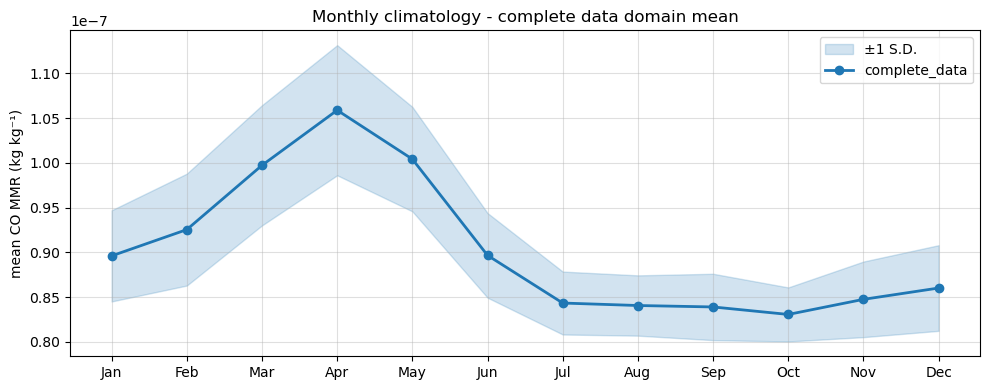

Saved -> ../../Figures/climatology\complete_domain_mean_monthly_climatology.png
          mean        std
Jan 8.9609e-08 5.0911e-09
Feb 9.2544e-08 6.2483e-09
Mar 9.9725e-08 6.7140e-09
Apr 1.0588e-07 7.2674e-09
May 1.0041e-07 5.8340e-09
Jun 8.9665e-08 4.7248e-09
Jul 8.4341e-08 3.5134e-09
Aug 8.4065e-08 3.3671e-09
Sep 8.3904e-08 3.7058e-09
Oct 8.3068e-08 3.0177e-09
Nov 8.4754e-08 4.2214e-09
Dec 8.6018e-08 4.7828e-09


In [2]:
# Monthly climatology of the complete field (domain-mean by calendar month)
obs_ts = field.mean(("lat", "lon")).values

month_num = pd.DatetimeIndex(field.time.values).month
obs_by_month = pd.Series(obs_ts, index=month_num).groupby(level=0)
obs_clim = obs_by_month.mean()
obs_std = obs_by_month.std()

fig, ax = plt.subplots(figsize=(10, 4))
ax.fill_between(mnames, obs_clim.values - obs_std.values, obs_clim.values + obs_std.values,
                color="#1f77b4", alpha=0.2, label="±1 S.D.")
ax.plot(mnames, obs_clim.values, "o-", lw=2, color="#1f77b4", label="complete_data")

ax.set_ylabel("mean CO MMR (kg kg⁻¹)")
ax.set_title("Monthly climatology - complete data domain mean")
ax.legend(); ax.grid(alpha=0.4)
plt.tight_layout()
out = os.path.join(FIG_DIR, f"{TAG}_domain_mean_monthly_climatology.png")
fig.savefig(out, dpi=150, bbox_inches="tight")
plt.show()
print("Saved ->", out)

print(pd.DataFrame({"mean": obs_clim.values, "std": obs_std.values}, index=mnames)
        .to_string(float_format="{:.4e}".format))

## Spatial climatology: average map for each calendar month

In [3]:
# (month, lat, lon): average of all Januaries, all Februaries, ...
clim = field.groupby("time.month").mean("time")
n_years = field.groupby("time.month").count("time").isel(lat=0, lon=0).values
print("Years averaged per month:", dict(zip(mnames, n_years.tolist())))
print("Climatology shape:", clim.shape, clim.dims)
print(f"Range: {float(clim.min()):.4e} - {float(clim.max()):.4e} kg/kg")

# consistency with the domain-mean climatology above
print(f"Max |domain mean of maps - domain-mean climatology| = "
      f"{np.abs(clim.mean(('lat', 'lon')).values - obs_clim.values).max():.3e}")

Years averaged per month: {'Jan': 23, 'Feb': 23, 'Mar': 23, 'Apr': 23, 'May': 23, 'Jun': 23, 'Jul': 23, 'Aug': 23, 'Sep': 23, 'Oct': 23, 'Nov': 23, 'Dec': 23}
Climatology shape: (12, 36, 61) ('month', 'lat', 'lon')
Range: 7.3514e-08 - 1.2302e-07 kg/kg
Max |domain mean of maps - domain-mean climatology| = 1.323e-23


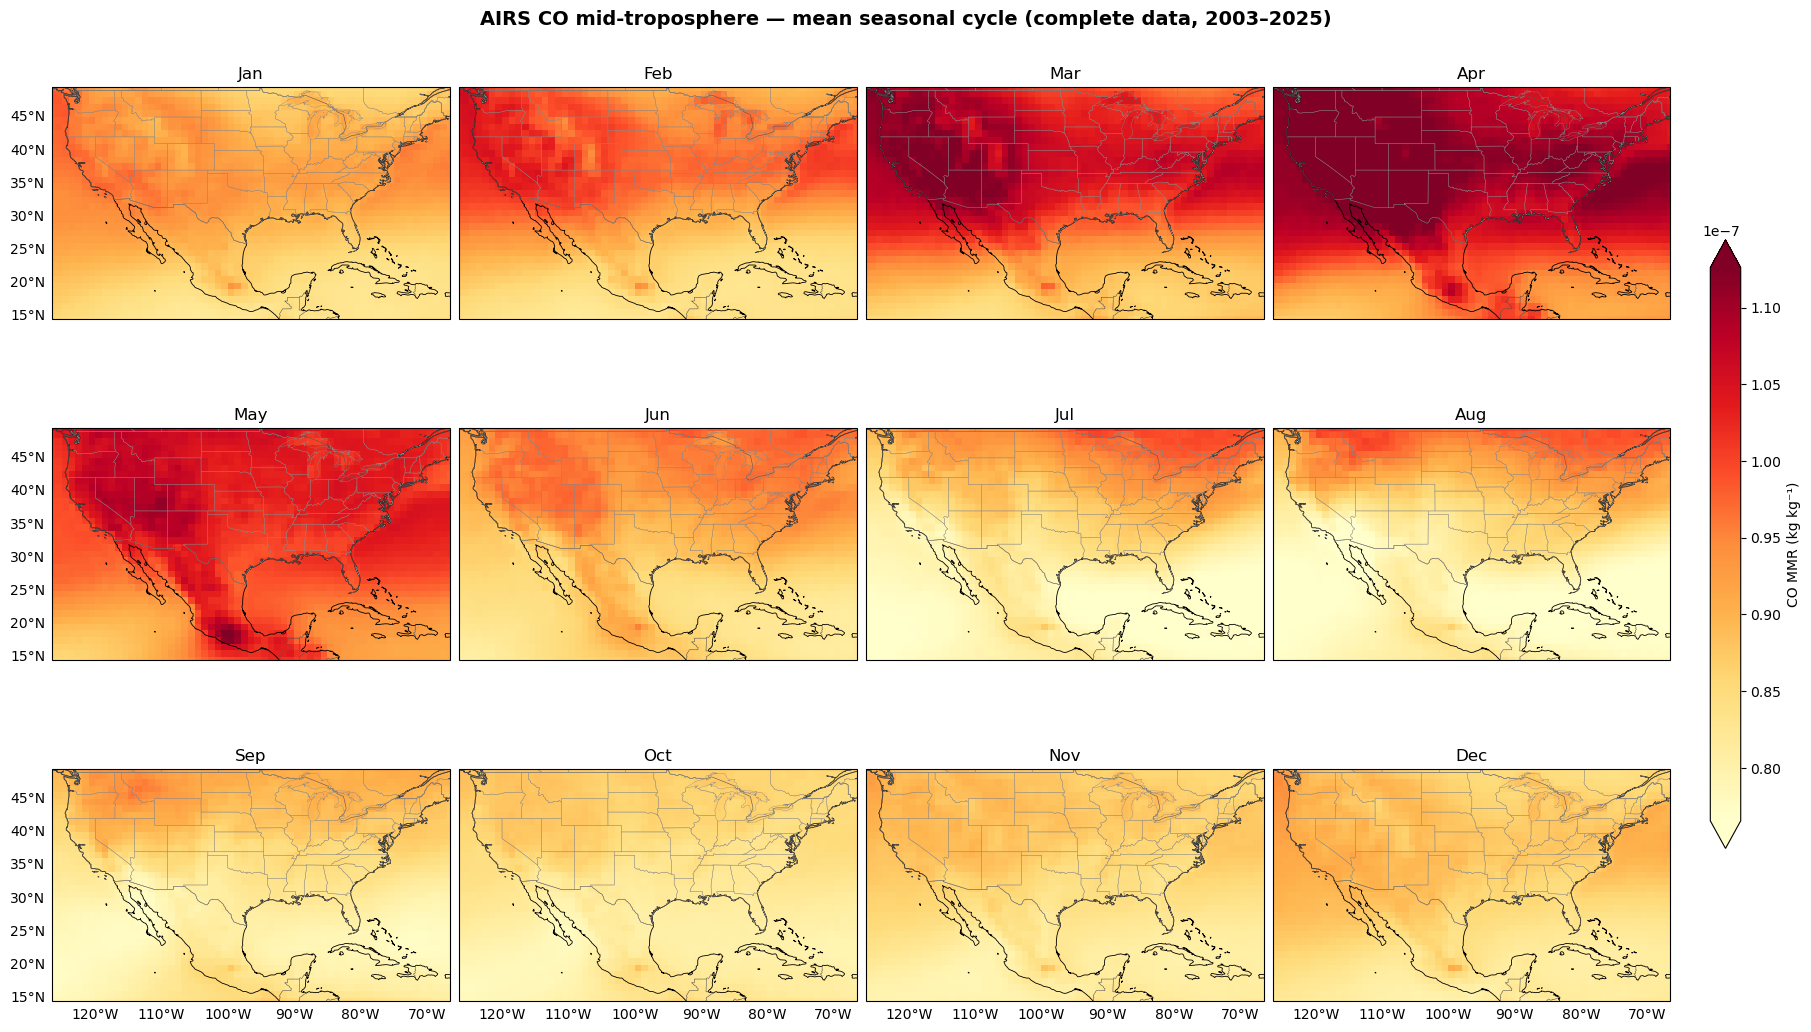

Saved -> ../../Figures/climatology\complete_monthly_maps.png


In [4]:
lons, lats = clim.lon.values, clim.lat.values
ext = [float(lons.min()), float(lons.max()), float(lats.min()), float(lats.max())]

# one shared colour scale for all 12 panels so months are directly comparable

cmap = "YlOrRd"
vmin, vmax = np.nanpercentile(clim.values, [2, 98])

fig, axes = plt.subplots(3, 4, figsize=(18, 10.5),
                         subplot_kw={"projection": ccrs.PlateCarree()}, constrained_layout=True)
for m, ax in enumerate(axes.flat, start=1):
    ax.set_extent(ext, crs=ccrs.PlateCarree())
    ax.add_feature(cfeature.COASTLINE, linewidth=0.6, edgecolor="k")
    ax.add_feature(cfeature.BORDERS,   linewidth=0.4, edgecolor="#555")
    ax.add_feature(cfeature.STATES,    linewidth=0.25, edgecolor="#888")
    pcm = ax.pcolormesh(lons, lats, clim.sel(month=m).values, transform=ccrs.PlateCarree(),
                        cmap=cmap, vmin=vmin, vmax=vmax, shading="nearest")
    gl = ax.gridlines(draw_labels=True, linewidth=0, color="none")
    gl.top_labels = gl.right_labels = False
    gl.left_labels = (m - 1) % 4 == 0
    gl.bottom_labels = m > 8
    ax.set_title(mnames[m - 1], fontsize=12)

cb = fig.colorbar(pcm, ax=axes, orientation="vertical", shrink=0.6, pad=0.02, extend="both")
cb.set_label("CO MMR (kg kg⁻¹)", fontsize=10)
fig.suptitle("AIRS CO mid-troposphere — mean seasonal cycle (complete data, "
             f"{pd.Timestamp(field.time.values[0]):%Y}–{pd.Timestamp(field.time.values[-1]):%Y})",
             fontsize=14, fontweight="bold")
out = os.path.join(FIG_DIR, f"{TAG}_monthly_maps.png")
fig.savefig(out, dpi=150, bbox_inches="tight")
plt.show()
print("Saved ->", out)

## Save the stacked 12-month cycle to `mean_seasonal_cycle.nc`

In [5]:
cycle = clim.transpose("month", "lat", "lon").rename("co_mmr_midtrop")
cycle = cycle.assign_coords(month_name=("month", mnames))
cycle.attrs = {
    "long_name": "Mean seasonal cycle of AIRS CO mid-troposphere MMR (complete field)",
    "units": "kg kg-1",
    "source": IN_NC,
    "period": f"{pd.Timestamp(field.time.values[0]):%Y-%m} to {pd.Timestamp(field.time.values[-1]):%Y-%m}",
    "method": "per-pixel average of all years for each calendar month",
}
cycle.to_netcdf(OUT_NC)
print("Saved ->", os.path.abspath(OUT_NC))
print(xr.open_dataarray(OUT_NC))

Saved -> D:\AIRS\harmonic-analysis\Scripts\climatology\mean_seasonal_cycle.nc
<xarray.DataArray 'co_mmr_midtrop' (month: 12, lat: 36, lon: 61)> Size: 211kB
[26352 values with dtype=float64]
Coordinates:
  * month       (month) int64 96B 1 2 3 4 5 6 7 8 9 10 11 12
  * lat         (lat) float32 144B 14.5 15.5 16.5 17.5 ... 46.5 47.5 48.5 49.5
  * lon         (lon) float32 244B -126.5 -125.5 -124.5 ... -68.5 -67.5 -66.5
    month_name  (month) <U3 144B ...
Attributes:
    long_name:  Mean seasonal cycle of AIRS CO mid-troposphere MMR (complete ...
    units:      kg kg-1
    source:     complete_data.nc
    period:     2003-01 to 2025-12
    method:     per-pixel average of all years for each calendar month
